# Kernel Density Estimation

I implemented Gaussian and rectangular kernels and compared fixed bandwidths with Scott and Silverman bandwidths. The checks include comparison with SciPy.

## Estimator Design

KDE estimates density by averaging kernels centered on training points. This implementation supports Gaussian and rectangular kernels and uses bandwidth to control their spread.

## Unit Tests

In [1]:
%load_ext autoreload
%autoreload 2
# No need to restart the notebook upon change thanks to autoreload

import numpy as np
from KDEstimator import KDEstimator

Test Scott and Silverman Bandwidth

In [ ]:
# this data has standard deviation 1 along each column
x_data= np.array([
    [0, 2],
    [2, 0],
    [0, 2],
    [2, 0]
])

# create two KDEstimator objects
kde1 = KDEstimator(bump='Gauss', bandwidth='Silverman')
kde2 = KDEstimator(bump='Gauss', bandwidth='Scott')

# fit the data
kde1.fit(x_data)
kde2.fit(x_data)

## M=4, N=2, avg_σ=1
calculated_silverman = (4/(16))**(1/6)
calculated_scott = 4**(-1/6)

assert calculated_silverman == kde1.h
assert calculated_scott == kde2.h

Test Gaussian Bump

In [4]:
import numpy as np
from scipy.stats import multivariate_normal

mean = np.zeros(2)  
covariance = np.eye(2)  
scipy_norm = multivariate_normal.pdf(x_data, mean=mean, cov=covariance)
our_norm = kde1.g(x_data)

# Test the implementation
assert np.allclose(our_norm, scipy_norm, atol=1e-4), "PDF values do not match expected values."

Test Rectangular Bump

In [5]:
x_val = np.array([
    [0, -0.6, 0.6],
    [0, -0.3, 0.3],
    [0.5, -0.5, 0.5],
    [0, 0.1, 0.4],
    [3, -2, 0]
])
kde1 = KDEstimator(bump='Rect', bandwidth='Silverman')
assert np.all(kde1.g(x_val) == np.array([0, 1, 1, 1, 0]))

## End-to-end Tests

### Test Gaussian Kernel with Silverman

Note that because Scipy computes the entire covariance matrix (doesn't make a standard normal assumption), we have allowed for a 1% error. This is also why we will skip testing a float bandwidth (but it should work anyway).

In [6]:
from scipy.stats import gaussian_kde

np.random.seed(42)
x_data = np.random.rand(3000, 2)

kde = KDEstimator(bump='Gauss', bandwidth='Silverman')
kde.fit(x_data)
my_res = kde.transform(x_data)

kernel = gaussian_kde(x_data.T, bw_method='silverman')
res = np.array(kernel(x_data.T))

np.allclose(res, my_res, rtol=0.01)

True

### Test Gaussian Kernel with Scott

In [7]:
np.random.seed(42)
x_data = np.random.rand(3000, 2)

kde = KDEstimator(bump='Gauss', bandwidth='Scott')
my_res = kde.fit_transform(x_data)

kernel = gaussian_kde(x_data.T, bw_method='scott')
res = np.array(kernel(x_data.T))

np.allclose(res, my_res, rtol=0.01)

True

#### Test Gaussian Kernel with Float Bandwidth

In [8]:
# Should yield no error
kde = KDEstimator(bump='Gauss', bandwidth=0.5)
kde.fit(x_data)
my_res = kde.transform(x_data)

## Comparing Density Surfaces

In [11]:
from sklearn import datasets
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

In [13]:
def plot_3d(x_data, *, densities, titles):
    x1_min, x1_max = np.min(x_data[:, 0]), np.max(x_data[:, 0])
    x2_min, x2_max = np.min(x_data[:, 1]), np.max(x_data[:, 1])

    x1 = np.linspace(x1_min, x1_max, 100)
    x2 = np.linspace(x2_min, x2_max, 100)
    
    x1, x2 = np.meshgrid(x1, x2)
    
    # convert the meshgrid into a (m, n) array to allow evaluation by the model
    x_plot = np.c_[x1.ravel(), x2.ravel()]
    
    # densities is a list of fitted kde instances.
    z = [kde.transform(x_plot) for kde in densities]
    
    # put z in meshgrid shape as the plot function assumes that
    z = [probs.reshape(x1.shape) for probs in z]
    
    # Number of subplots
    num_subplots = len(titles)

    # Creating subplots
    plt.style.use('dark_background')
    fig, axs = plt.subplots(1, num_subplots, figsize=(6 * num_subplots, 7), dpi=140, subplot_kw={'projection': '3d'})

    # for each density we want a plot
    for i, ax in enumerate(axs):
        ax.plot_surface(x1, x2, z[i], cmap='plasma', alpha=0.8)
        
        # Set title and labels
        ax.set_title(titles[i])
        ax.set_xlabel('Feature X')
        ax.set_ylabel('Feature Y')
        ax.set_zlabel('Z-axis', labelpad=1)
        # turn off grid and z-axis ticks
        ax.grid(False)
        ax.set_zticks([])
        # turn off planes
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        # change view angle
        ax.view_init(elev=50, azim=130)

    # Show the plot
    plt.show()

#### 1. Compare the Choice of Bandwidth

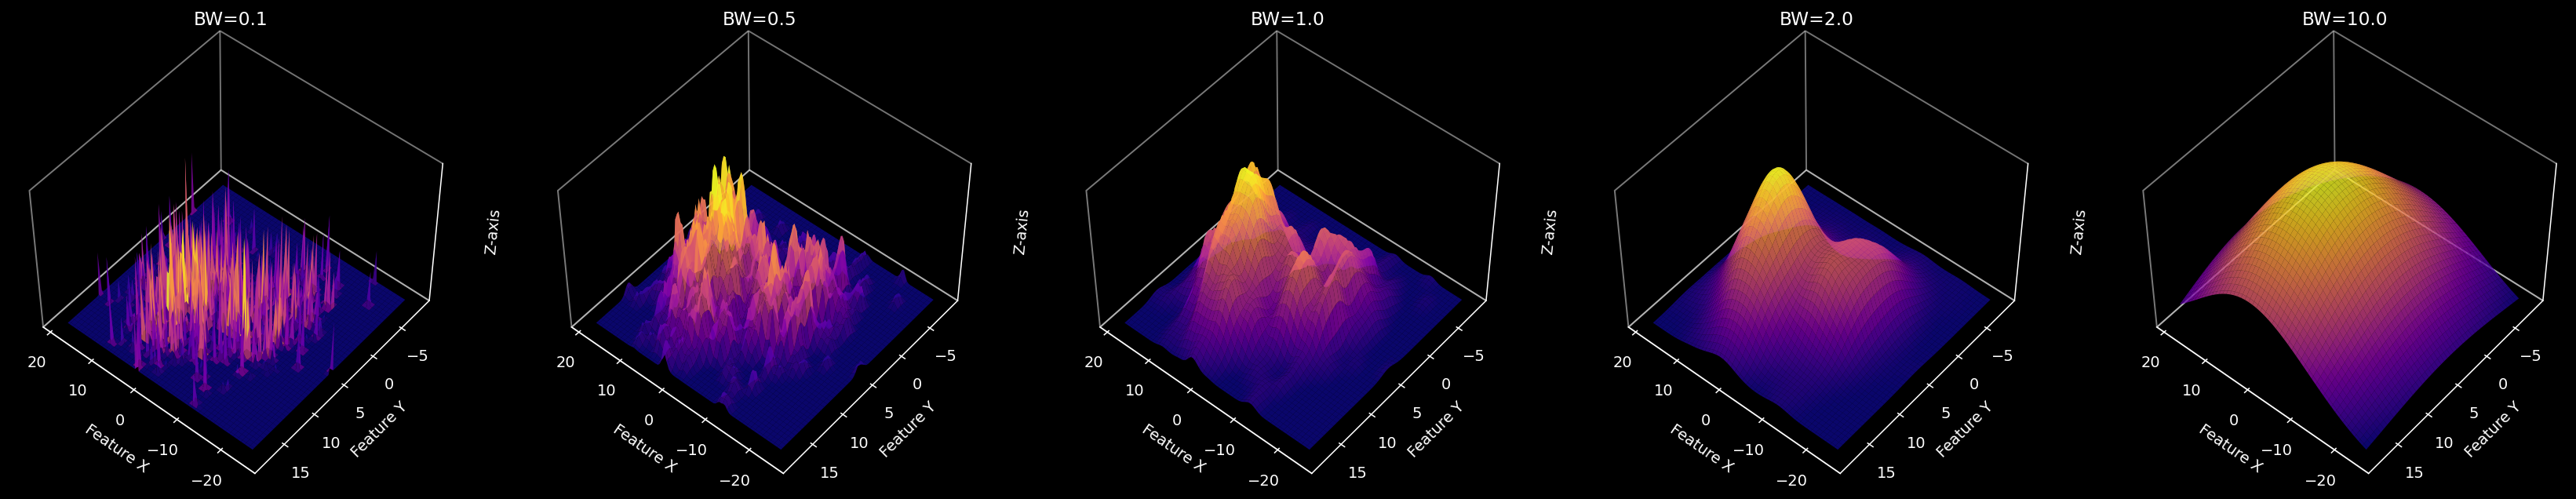

In [14]:
# Generate some random data
x_data, _= datasets.make_blobs(n_samples=1000, centers=3, cluster_std=4.0, center_box=(-10,10), random_state=20)


kde1 = KDEstimator(bump='Gauss', bandwidth=0.1)
kde1.fit(x_data)

kde2 = KDEstimator(bump='Gauss', bandwidth=0.5)
kde2.fit(x_data)

kde3 = KDEstimator(bump='Gauss', bandwidth=1.0)
kde3.fit(x_data)

kde4 = KDEstimator(bump='Gauss', bandwidth=2.0)
kde4.fit(x_data)

kde5 = KDEstimator(bump='Gauss', bandwidth=10.0)
kde5.fit(x_data)


plot_3d(x_data, densities=[kde1, kde2, kde3, kde4, kde5], titles=['BW=0.1', 'BW=0.5', 'BW=1.0', 'BW=2.0', 'BW=10.0'])

A smaller bandwidth preserves local detail and can produce a noisy surface. A larger bandwidth smooths the estimate and can obscure separate peaks.

#### 2. Compare Scott and Silverman

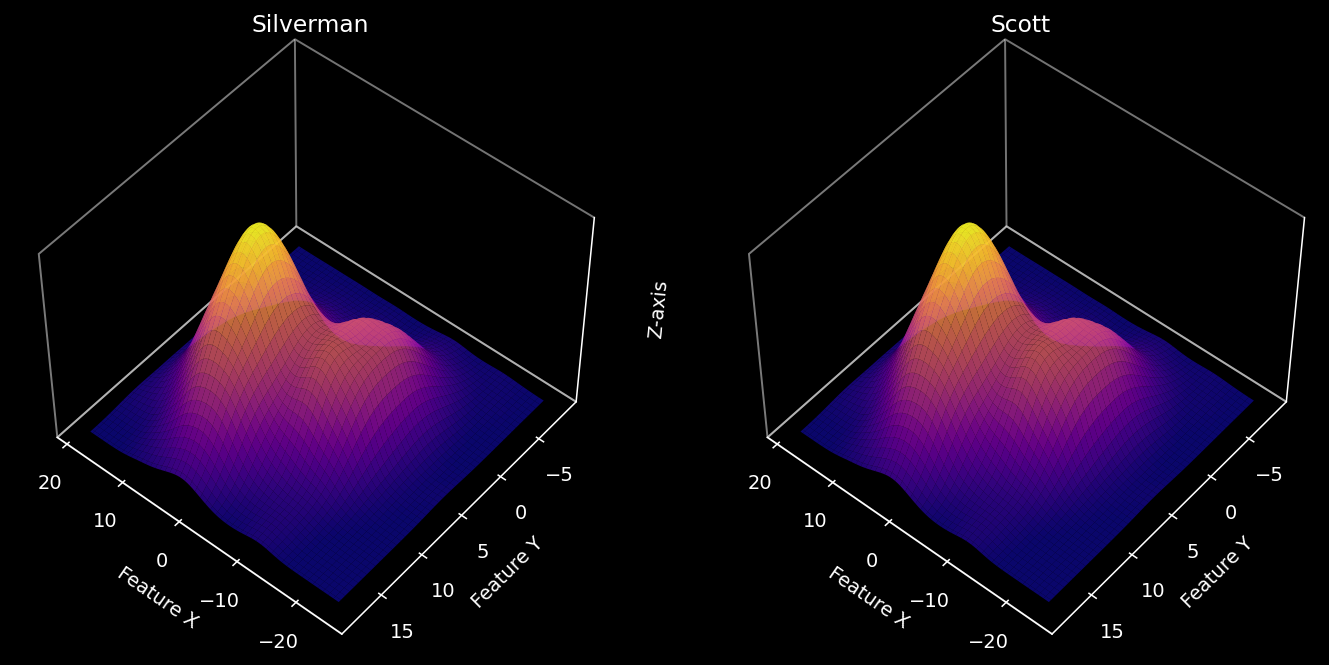

In [15]:

kde1 = KDEstimator(bump='Gauss',bandwidth='Silverman')
kde1.fit(x_data)

kde2 = KDEstimator(bump='Gauss', bandwidth='Scott')
kde2.fit(x_data)

plot_3d(x_data, densities=[kde1, kde2], titles=['Silverman', 'Scott'])

For two features, the Scott and Silverman factors used in this implementation coincide.

#### 3. Compare Bump Functions

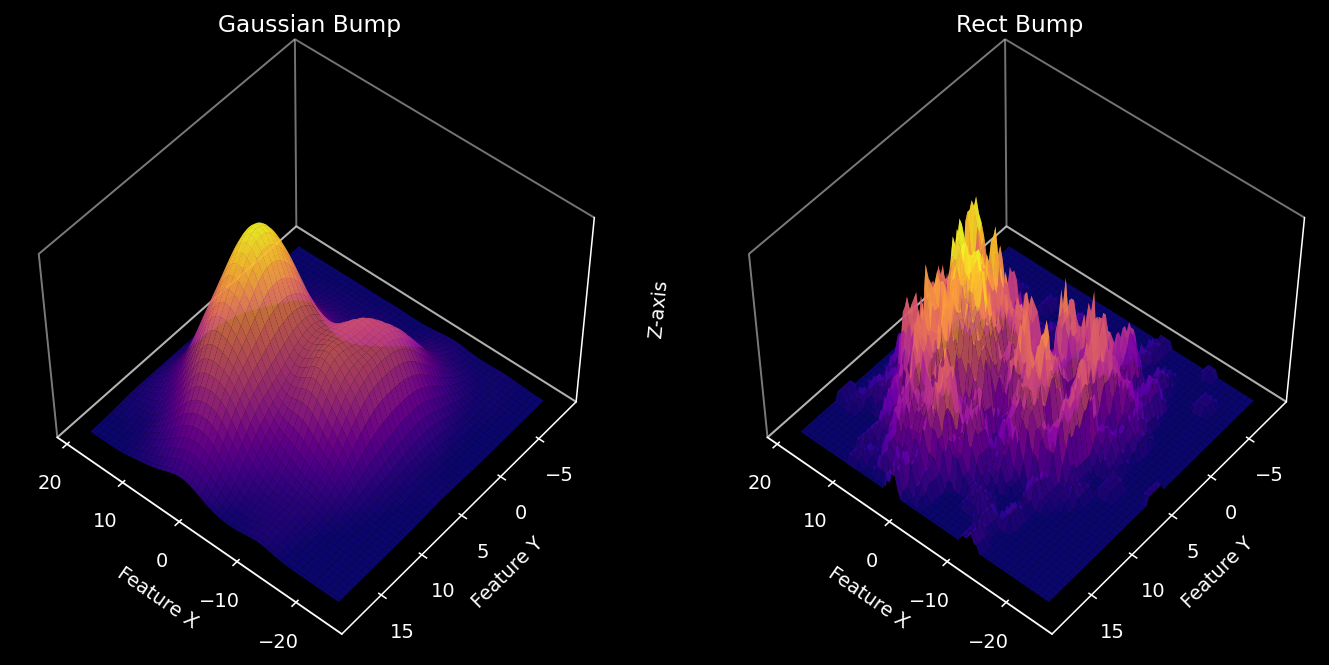

In [16]:

kde1 = KDEstimator(bump='Gauss')
kde1.fit(x_data)

kde2 = KDEstimator(bump='Rect')
kde2.fit(x_data)

plot_3d(x_data, densities=[kde1, kde2], titles=['Gaussian Bump', 'Rect Bump'])

The rectangular kernel creates step changes at its boundary. The Gaussian kernel yields a smooth density surface.

#### Rectangular Kernel with a Larger Bandwidth

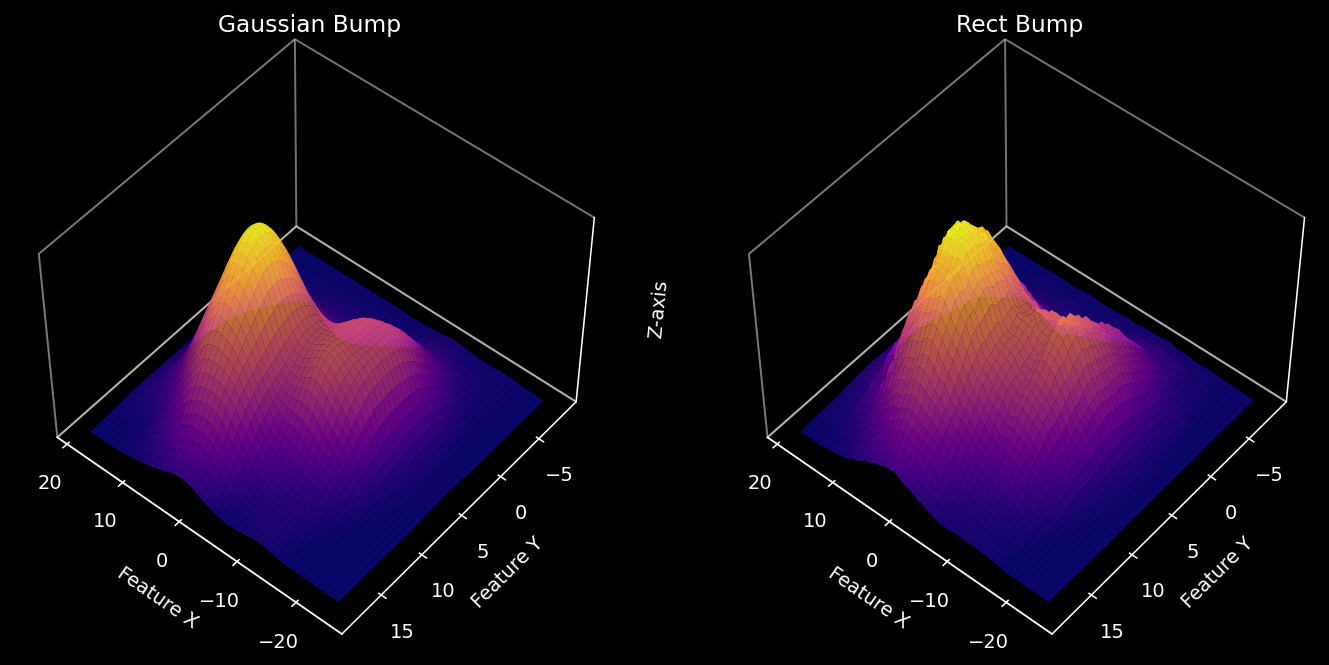

In [27]:
kde1 = KDEstimator(bump='Gauss')
kde1.fit(x_data)

kde2 = KDEstimator(bump='Rect', bandwidth=9.0)
kde2.fit(x_data)

plot_3d(x_data, densities=[kde1, kde2], titles=['Gaussian Bump', 'Rect Bump'])